# 1D advection: the linear and the nonlinear problem

Two equations, one solver. First the linear advection equation

$$\frac{\partial u}{\partial t} + c\,\frac{\partial u}{\partial x} = 0,$$

in which $c$ is a given constant, and then the nonlinear one

$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = 0,$$

in which the speed is the solution itself. Both are differenced in the same way: forward in time, backward in space.

### Notation

$$x \to i\,, \qquad t \to n,$$

so the value at the $i$-th point and the $n$-th time level is $u_i^{\,n}$, stored as `u[i, n]`, the same convention used for $T_i^{\,n}$ in the heat equation notebooks. The mesh steps are `dx` and `dt` in the code, and the dimensionless group that controls everything here is the Courant number

$$C = \frac{c\,\Delta t}{\Delta x}.$$

The grid, the initial and boundary conditions and the time levels to plot are set up once, below, and both problems use them.

## Set-up: grid, ICs/BCs, time levels:

In [43]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

# This is for the 3D surface at the end
from mpl_toolkits.mplot3d import Axes3D

### 1. Domain Definition (grid creation):

In [44]:
# Advection speed for the linear problem
c = 1.0

# Steps
dx = 0.025   # Step size -> delta_x
dt = 0.0125  # Time step -> delta_t

# The Courant number
C_factor = c*dt/dx # should be <= 1 to have stable solutions
print("Courant number is:  ", np.array(C_factor).round(5))

Courant number is:   0.5


In [45]:
# Limit for the spatial vector
a = 2.0

# Limit for the time vector
b = 0.5

# Axes
# Spatial axis
x = np.arange(0., a + dx, dx)

# Time axis, rounding it to 5 figs. is for plotting only
t = np.arange(0., b + dt, dt).round(5)

# Number of points on each axis
ni = len(x)
nt = len(t)

#print(ni, nt)

### 2. Set up ICs/BCs:

The initial condition is the hat function used by Barba: $u = 2$ between
$x = 0.5$ and $x = 1$, and $u = 1$ everywhere else. It is deliberately not
smooth, because the corners are what the scheme finds difficult.

In [46]:
def hat_profile(x_vec, x_left = 0.5, x_right = 1.0, u_low = 1.0, u_high = 2.0):
    
    u_vec = u_low*np.ones_like(x_vec)

    u_vec[(x_vec >= x_left) & (x_vec <= x_right)] = u_high
    
    return u_vec

In [47]:
# Initial conditions
ics = hat_profile(x) # this is the initial u at t=0

# Boundary Conditions
bcs = [1., 1.] # u = 1 at x=0, and x=a, the far-field value

#print(ics.min(), ics.max())

### 3. The time levels we will plot:

The same levels are used for both problems, so the two sets of curves can be
compared directly.

In [48]:
# Columns of u to draw
n_show = [0, 8, 16, 24, 32, nt - 1]

print(t[n_show])

[0.  0.1 0.2 0.3 0.4 0.5]


# Part I. Linear advection (FTBS: Forward in Time, Backward in Space)

$$
\frac{\partial u}{\partial t} + c\,\frac{\partial u}{\partial x} = 0,
$$
$$
u_t = -c\,u_x,
$$
$\Rightarrow$ *time evolution = constant $\times$ slope of the function
(hyperbolic term)*.

## Discretization

**Forward Difference in time:**
$$
u_t \approx \frac{u_i^{\,n+1} - u_i^{\,n}}{\Delta t} + \mathcal{O}(\Delta t).
$$

**Backward Difference in space:**
$$
u_x \approx \frac{u_i^{\,n} - u_{i-1}^{\,n}}{\Delta x} + \mathcal{O}(\Delta x).
$$

Putting them into the equation,

$$
\frac{u_i^{\,n+1} - u_i^{\,n}}{\Delta t}
+ c\,\frac{u_i^{\,n} - u_{i-1}^{\,n}}{\Delta x} = 0,
$$

and the only unknown is $u_i^{\,n+1}$, so

$$
u_i^{\,n+1} = u_i^{\,n} - C\left(u_i^{\,n} - u_{i-1}^{\,n}\right)
            = (1 - C)\,u_i^{\,n} + C\,u_{i-1}^{\,n},
\qquad C = \frac{c\,\Delta t}{\Delta x}.
$$

Written the second way, the new value is a weighted average of two old ones.
The weights are both positive when $0 \le C \le 1$, which is the stability
condition for this scheme.

### 1. Solution matrix, with the ICs/BCs in place:

In [49]:
# Empty matrix with the correct size
u_lin = np.zeros((ni, nt))

# Fill up the initial conditions
u_lin[:, 0] = ics

# Fill up the boundary conditions
u_lin[0 , :] = bcs[0]
u_lin[-1, :] = bcs[1]

#print(u_lin.round(4).T)

### 2. Fill up the inner elements of the matrix using our explicit formula:

$$u_i^{\,n+1} = u_i^{\,n} - C\left(u_i^{\,n} - u_{i-1}^{\,n}\right)$$

In [50]:
# outer loop (time loop -> index n)
for n in range(1, nt): # From 1 as we already have the ICs

    # inner loop (spatial loop -> index i)
    for i in range(1, ni - 1): # From 1 to ni-1 as we already have the BCs set
        # Explicit formula
        u_lin[i, n] = u_lin[i, n-1] - C_factor*(u_lin[i, n-1] - u_lin[i-1, n-1])

### 3. Another approach:

- Now we use the same march, but use indexing instead of the inner loop.

- The spatial loop above does the same operation to every interior point, so it can be replaced by one slice.

- The time loop cannot: each level needs the one before it.

In [51]:
# Same matrix, built without the inner loop
u_lin_vec = np.zeros((ni, nt))
u_lin_vec[:, 0] = ics
u_lin_vec[0 , :] = bcs[0]
u_lin_vec[-1, :] = bcs[1]

for n in range(1, nt):
    # the whole interior at once: i = 1, ..., ni-2
    u_lin_vec[1:-1, n] = (u_lin_vec[1:-1, n-1] - C_factor*(u_lin_vec[1:-1, n-1] - u_lin_vec[:-2, n-1]))

# The two marches have to agree to machine precision
print("The largest difference between both approacher is:", np.abs(u_lin - u_lin_vec).max())

The largest difference between both approacher is: 0.0


### 4. Plotting the solution for $u(x,t)$:

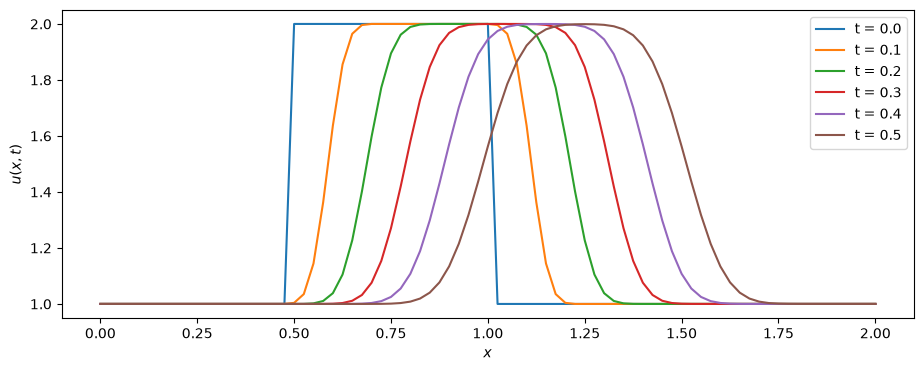

In [52]:
# Fig environment
plt.figure(figsize=(11,4))

for n in n_show:
    plt.plot(x, u_lin[:, n], label = f"t = {t[n]}")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.legend()

plt.show()

### 5. Plotting against the exact solution:

The exact solution is the initial profile translated, $u(x,t) = u_0(x - ct)$, so the two curves should sit on top of each other and every difference between them was put there by the scheme.

In [53]:
# The exact solution at the final time
u_exact = hat_profile(x - c*t[-1])

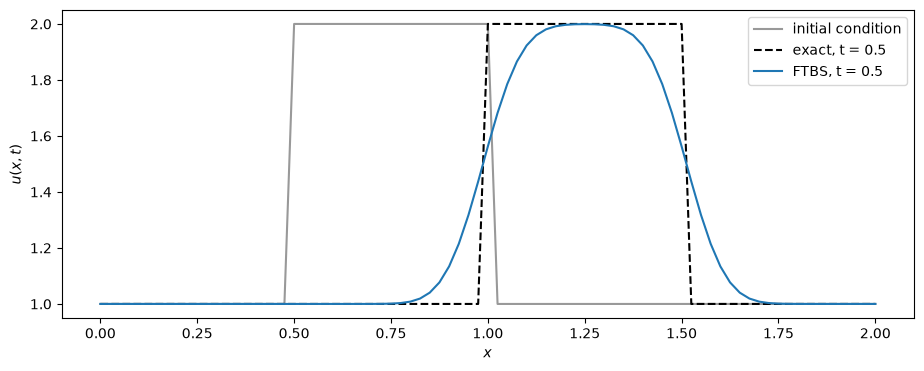

In [54]:
plt.figure(figsize=(11,4))

plt.plot(x, ics, color = "0.6", label = "initial condition")
plt.plot(x, u_exact, "k--", label = f"exact, t = {t[-1]}")
plt.plot(x, u_lin[:, -1], label = f"FTBS, t = {t[-1]}")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.legend()

plt.show()

### 6. The role of the CFL number:

The modified equation of this scheme is

$$u_t + c\,u_x = \alpha_{\rm num}\,u_{xx},
\qquad \alpha_{\rm num} = \frac{c\,\Delta x}{2}\,(1 - C),$$

so the smearing should grow as $C$ is reduced and disappear at $C = 1$.

The function below marches to a fixed physical time for a given $C$, so the three runs can be compared at the same instant.

In [55]:
def march_linear(x_vec, c_speed, C_target, t_end):

    dx_loc = x_vec[1] - x_vec[0]
    dt_loc = C_target*dx_loc/c_speed
    
    n_steps = int(round(t_end/dt_loc))

    u_end = hat_profile(x_vec)

    for n in range(n_steps):
        u_old = u_end.copy()
        u_end[1:-1] = u_old[1:-1] - C_target*(u_old[1:-1] - u_old[:-2])

    return u_end, n_steps

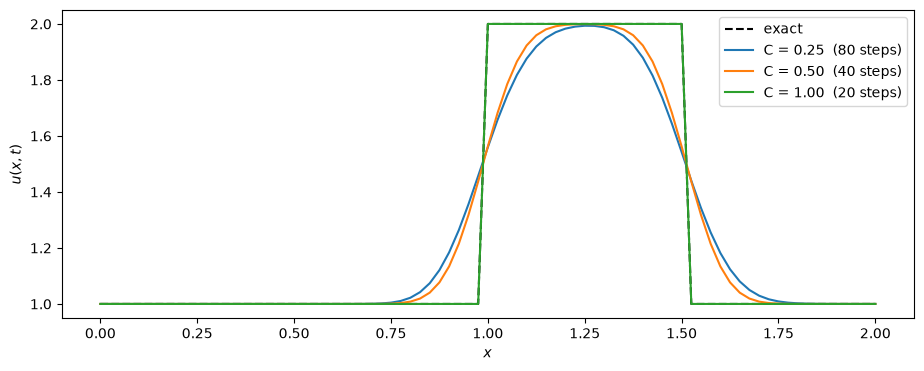

In [69]:
plt.figure(figsize=(11,4))

plt.plot(x, hat_profile(x - c*b), "k--", label = "exact")

for C_try in [0.25, 0.50, 1.00]:
    u_try, n_steps = march_linear(x, c, C_try, b)
    plt.plot(x, u_try, label = f"C = {C_try:.2f}  ({n_steps} steps)")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.legend()

plt.show()

### 7. What if the CFL condition is not satisfied?

For $C > 1$ the foot of the characteristic falls outside the stencil, the weights $(1-C)$ and $C$ stop being both positive, and the amplification factor

$$|G|^2 = 1 - 2\,C\,(1-C)\,(1-\cos\theta)$$

exceeds 1 for every mode. We run the same march at $C = 1.2$ and see it.

In [70]:
# Evaluate solution:

u_bad, n_bad = march_linear(x, c, 1.20, 0.25)

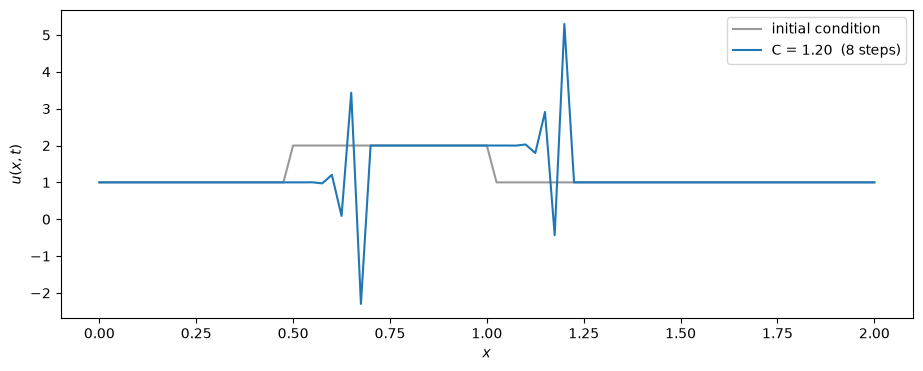

In [71]:
plt.figure(figsize=(11,4))

plt.plot(x, ics, color = "0.6", label = "initial condition")
plt.plot(x, u_bad, label = f"C = 1.20  ({n_bad} steps)")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.legend()

plt.show()

#print("The largest value on the mesh is:", np.abs(u_bad).max())

### 8. Amplification factor per mode:

The amplification show  

Plot $|G|$ against $\theta = k\,\Delta x$ for a few Courant numbers and read off which modes grow.

In [72]:
# Theta axis
theta = np.linspace(0., np.pi, 400)

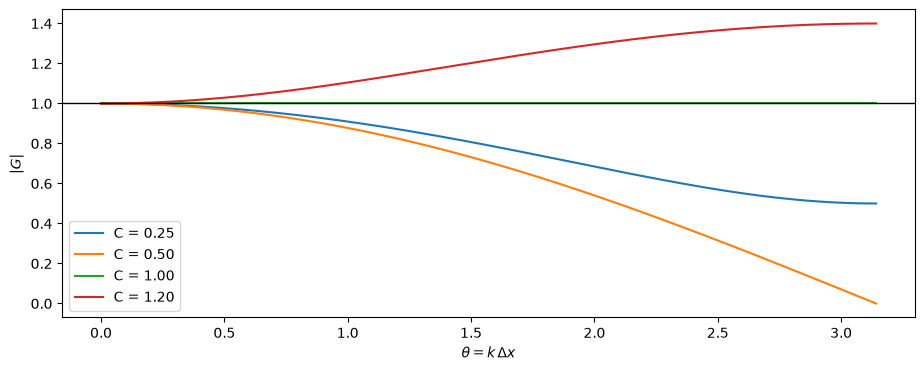

In [73]:
plt.figure(figsize=(11,4))

for C_try in [0.25, 0.50, 1.00, 1.20]:
    G_mod = np.sqrt(1. - 2.*C_try*(1. - C_try)*(1. - np.cos(theta)))
    plt.plot(theta, G_mod, label = f"C = {C_try:.2f}")

plt.axhline(1.0, color = "k", lw = 1.0)

plt.xlabel(r"$\theta = k \, \Delta x$")
plt.ylabel(r"$|G|$")

plt.legend()

plt.show()

# Part II. Nonlinear advection

$$
\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = 0.
$$

The constant $c$ has been replaced by $u$ itself. This is the inviscid Burgers
equation written in non-conservative form.

## Discretization

The same two differences as before, with $c \to u_i^{\,n}$:

$$
\frac{u_i^{\,n+1} - u_i^{\,n}}{\Delta t}
+ u_i^{\,n}\,\frac{u_i^{\,n} - u_{i-1}^{\,n}}{\Delta x} = 0,
$$

$$
u_i^{\,n+1} = u_i^{\,n}
- u_i^{\,n}\,\frac{\Delta t}{\Delta x}\left(u_i^{\,n} - u_{i-1}^{\,n}\right).
$$

One line of the code changes. The Courant number is now local,

$$C_i^{\,n} = \frac{u_i^{\,n}\,\Delta t}{\Delta x},$$

so the stability condition has to be read off the worst point on the mesh at
every step:

$$\Delta t \le \frac{\Delta x}{\max_i \left| u_i^{\,n} \right|}.$$

With the hat function the largest speed is 2, so the time step above gives a
largest local Courant number of 1, right on the limit. Halve it first.

### 1. Solution matrix, with the ICs/BCs in place:

In [74]:
# A smaller time step, because the fastest part of the hat moves at u = 2
dt_nl = 0.00625

t_nl = np.arange(0., b + dt_nl, dt_nl).round(5)
nt_nl = len(t_nl)

print("The largest local CFL number at t = 0:", round(float(ics.max()*dt_nl/dx), 5))

# Empty matrix with the correct size
u_nl = np.zeros((ni, nt_nl))

# Fill up the initial conditions
u_nl[:, 0] = ics

# Fill up the boundary conditions
u_nl[0 , :] = bcs[0]
u_nl[-1, :] = bcs[1]

n_show_nl = [0, 16, 32, 48, 64, nt_nl - 1]

#print(t_nl[n_show_nl])

The largest local CFL number at t = 0: 0.5


### 2. Fill up the inner elements of the matrix using the nonlinear formula:

$$u_i^{\,n+1} = u_i^{\,n}
- u_i^{\,n}\,\frac{\Delta t}{\Delta x}\left(u_i^{\,n} - u_{i-1}^{\,n}\right)$$

In [75]:
# outer loop (time loop -> index n)
for n in range(1, nt_nl): # From 1 as we already have the ICs

    # inner loop (spatial loop -> index i)
    for i in range(1, ni - 1): # From 1 to ni-1 as we already have the BCs set
        # Explicit formula, with the speed taken from the solution itself
        u_nl[i, n] = (u_nl[i, n-1]
                      - u_nl[i, n-1]*dt_nl/dx*(u_nl[i, n-1] - u_nl[i-1, n-1]))

### 3. Plotting the solution for $u(x,t)$:

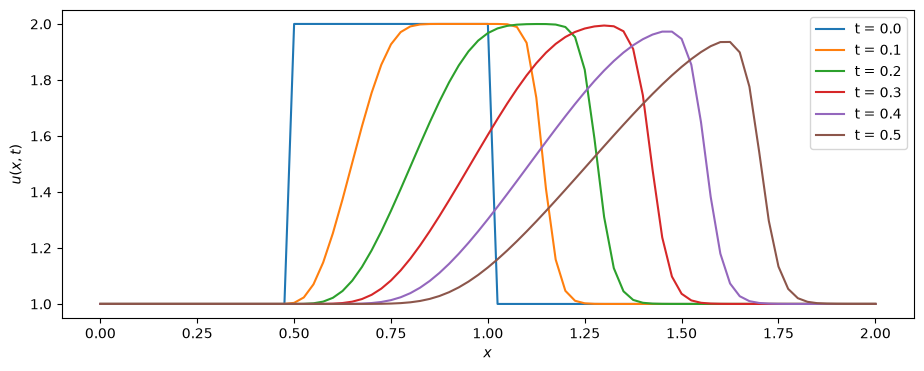

In [76]:
# Fig environment
plt.figure(figsize=(11,4))

for n in n_show_nl:
    plt.plot(x, u_nl[:, n], label = f"t = {t_nl[n]}")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.legend()

plt.show()

### 4. The largest local Courant (CFL) number:

For the linear problem $C$ was set once and never changed.

For a non-linear problem, it has to be monitored, because the stability of the next step depends on the solution the last step produced.

In [77]:
# Get max CFL number

C_max = u_nl.max(axis = 0)*dt_nl/dx

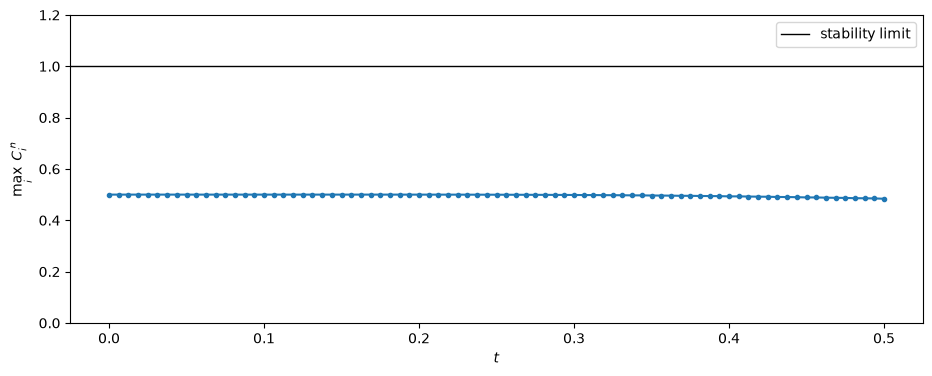

In [79]:
plt.figure(figsize=(11,4))

plt.plot(t_nl, C_max, "o-", ms = 3)
plt.axhline(1.0, color = "k", lw = 1.0, label = "stability limit")

plt.xlabel(r"$t$")
plt.ylabel(r"$\max_i \; C_i^{\,n}$")

plt.legend()
plt.ylim(0, 1.2)

plt.show()

### 5. Where is the front?

Each point of the profile travels at its own speed, so the front of the hat, which carries $u = 2$, should move twice as fast as the back, which carries $u = 1$.

Track the position where the solution crosses $u = 1.5$ and compare the slope with those two speeds.

The third reference line is the speed a shock between $u = 2$ and $u = 1$ should travel at (we will derive it later).

In [ ]:
def crossing(x_vec, u_vec, level = 1.5, side = "front"):

    above = u_vec > level
    
    idx = np.where(above[:-1] != above[1:])[0]

    if len(idx) == 0:
        return np.nan

    k = idx[-1] if side == "front" else idx[0]
    w = (level - u_vec[k])/(u_vec[k+1] - u_vec[k])

    x_cross = x_vec[k] + w*(x_vec[k+1] - x_vec[k])
    return x_cross

In [80]:
# Trach front and back of the profile
x_front = np.array([crossing(x, u_nl[:, n], 1.5, "front") for n in range(nt_nl)])
x_back  = np.array([crossing(x, u_nl[:, n], 1.5, "back" ) for n in range(nt_nl)])

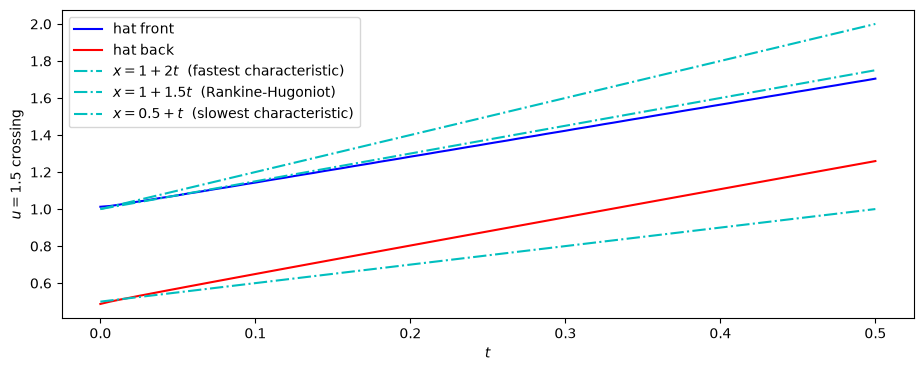

In [92]:
plt.figure(figsize=(11,4))

plt.plot(t_nl, x_front, "b-", label = "hat front")
plt.plot(t_nl, x_back , "r-", label = "hat back")

plt.plot(t_nl, 1.0 + 2.0*t_nl, "c-.", label = r"$x = 1 + 2t$  (fastest characteristic)")
plt.plot(t_nl, 1.0 + 1.5*t_nl, "c-." , label = r"$x = 1 + 1.5t$  (Rankine-Hugoniot)")
plt.plot(t_nl, 0.5 + 1.0*t_nl, "c-." , label = r"$x = 0.5 + t$  (slowest characteristic)")

plt.xlabel(r"$t$")
plt.ylabel(r"$u = 1.5$ crossing")

plt.legend()

plt.show()

# Comparison of the two problems: linear vs. non-linear

#### A. The same hat, carried by c and carried by u:

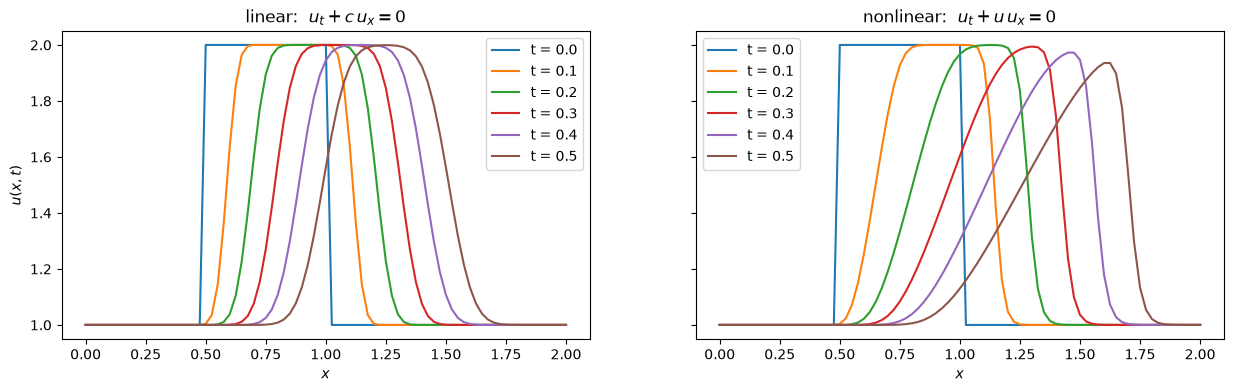

In [93]:
fig, ax = plt.subplots(1, 2, figsize = (15,4), sharey = True)

for n in n_show:
    ax[0].plot(x, u_lin[:, n], label = f"t = {t[n]}")

for n in n_show_nl:
    ax[1].plot(x, u_nl[:, n], label = f"t = {t_nl[n]}")

ax[0].set_title(r"linear:  $u_t + c \, u_x = 0$")
ax[1].set_title(r"nonlinear:  $u_t + u \, u_x = 0$")

for a in ax:
    a.set_xlabel(r"$x$")
    a.legend()

ax[0].set_ylabel(r"$u(x,t)$")

plt.show()

### Observations:

- In the linear problem the hat keeps its height and its width and moves at the single speed $c$.

- It loses its corners because the scheme is really solving an advection-diffusion equation with $\alpha_{\rm num} = \frac{1}{2} c\,\Delta x\,(1 - C)$. 

- At $C = 1$ that diffusivity is zero and the hat is reproduced exactly (one cell per step). At $C = 1.2$ nothing is reproduced at all.

- In the nonlinear problem, the hat changes shape. The part carrying $u = 2$ moves twice as fast as the part carrying $u = 1$, so the back of the hat stretches into a ramp and the front compresses into a step (not a numerical artefact). The exact solution of this equation develops a discontinuity (a shock) in finite time, and after it does, the classical solution has stopped existing.

- It keeps producing numbers, and later we will see that the numbers put the discontinuity in the wrong place, because the form we differenced is not conservative.